In [4]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
import seaborn as sns
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [8]:
from google.colab import files
uploaded = files.upload()
data = pd.read_csv('dava.csv')
data.head()

Saving dava.csv to dava (2).csv


,Unnamed: 0,Case Duration (Days),Number of Witnesses,Legal Fees (USD),Number of Evidence Items,Severity,Outcome
0,0,132,8,35206,49,2,0
1,1,300,12,46106,46,2,1
2,2,136,2,16411,31,1,1
3,3,101,1,7911,35,1,0
4,4,218,16,6734,33,1,0


In [11]:
# Sadece sayısal sütunları seçelim (k-means sayısal verilerle çalışır)
num_cols = data.select_dtypes(include=['int64', 'float64']).columns
df_num = data[num_cols]

print("📊 Kullanılan Sayısal Özellikler:")
print(num_cols)

# Eksik değer kontrolü
print("\n🧹 Eksik Değer Sayısı:")
print(df_num.isnull().sum())

# Eksik değer varsa ortalama ile doldur
df_num = df_num.fillna(df_num.mean())

# İlk 5 satırı kontrol et
df_num.head()


📊 Kullanılan Sayısal Özellikler:
Index(['Unnamed: 0', 'Case Duration (Days)', 'Number of Witnesses',
       'Legal Fees (USD)', 'Number of Evidence Items', 'Severity', 'Outcome'],
      dtype='object')

🧹 Eksik Değer Sayısı:
Unnamed: 0                  0
Case Duration (Days)        0
Number of Witnesses         0
Legal Fees (USD)            0
Number of Evidence Items    0
Severity                    0
Outcome                     0
dtype: int64


,Unnamed: 0,Case Duration (Days),Number of Witnesses,Legal Fees (USD),Number of Evidence Items,Severity,Outcome
0,0,132,8,35206,49,2,0
1,1,300,12,46106,46,2,1
2,2,136,2,16411,31,1,1
3,3,101,1,7911,35,1,0
4,4,218,16,6734,33,1,0


In [12]:
from sklearn.preprocessing import StandardScaler

# Ölçekleyici nesnesini oluştur
scaler = StandardScaler()

# Veriyi ölçeklendir
data_scaled = scaler.fit_transform(df_num)

print("✅ Veriler ölçeklendirildi!")
print("📊 İlk 5 satır (ölçeklenmiş):\n")
print(data_scaled[:5])


✅ Veriler ölçeklendirildi!
📊 İlk 5 satır (ölçeklenmiş):

[[-1.71481604 -0.70930867 -0.13975084  0.63876039  1.63452107  0.21570895
  -0.85096294]
 [-1.68017329  1.0377058   0.57692013  1.43228231  1.41774109  0.21570895
   1.1751393 ]
 [-1.64553055 -0.66771309 -1.21475729 -0.72951892  0.33384117 -1.05316721
   1.1751393 ]
 [-1.6108878  -1.03167444 -1.39392504 -1.34832041  0.62288115 -1.05316721
  -0.85096294]
 [-1.57624505  0.18499635  1.2935911  -1.43400622  0.47836116 -1.05316721
  -0.85096294]]


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


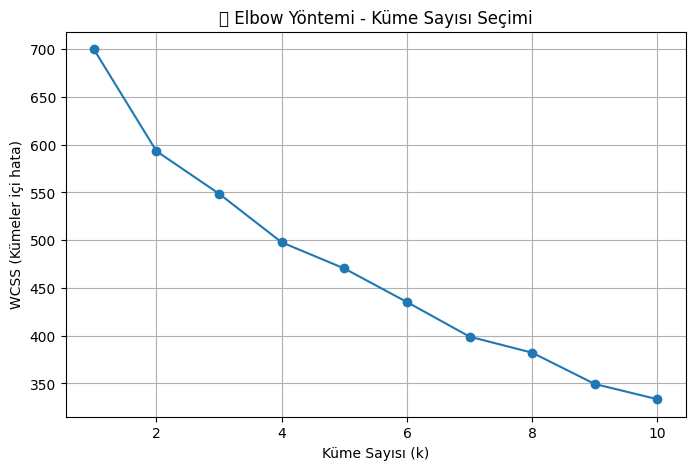

In [13]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

wcss = []  # WCSS = within-cluster sum of squares

# 1'den 10'a kadar farklı küme sayıları için WCSS hesaplayalım
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, init='k-means++', random_state=42)
    kmeans.fit(data_scaled)
    wcss.append(kmeans.inertia_)

# Elbow grafiğini çiz
plt.figure(figsize=(8,5))
plt.plot(range(1, 11), wcss, marker='o')
plt.title("📉 Elbow Yöntemi - Küme Sayısı Seçimi")
plt.xlabel("Küme Sayısı (k)")
plt.ylabel("WCSS (Kümeler içi hata)")
plt.grid(True)
plt.show()


In [14]:
from sklearn.cluster import KMeans

# Elbow grafiğinden bulduğun optimal k değerini buraya yaz 👇
k_optimal = 3  # Örneğin grafikte dirsek 3'teyse

# K-Means modelini oluştur ve veriye uygula
kmeans = KMeans(n_clusters=k_optimal, init='k-means++', random_state=42)
clusters = kmeans.fit_predict(data_scaled)

# Orijinal veriye küme bilgilerini ekle
data['Kume'] = clusters

print("✅ Kümeleme tamamlandı!")
print("\n📊 Her kümedeki veri sayısı:")
print(data['Kume'].value_counts())

# İlk 5 satırı görelim
data.head()


✅ Kümeleme tamamlandı!

📊 Her kümedeki veri sayısı:
Kume
1    40
2    38
0    22
Name: count, dtype: int64


,Unnamed: 0,Case Duration (Days),Number of Witnesses,Legal Fees (USD),Number of Evidence Items,Severity,Outcome,Kume
0,0,132,8,35206,49,2,0,1
1,1,300,12,46106,46,2,1,0
2,2,136,2,16411,31,1,1,2
3,3,101,1,7911,35,1,0,2
4,4,218,16,6734,33,1,0,0


/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 127919 (\N{DIRECT HIT}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


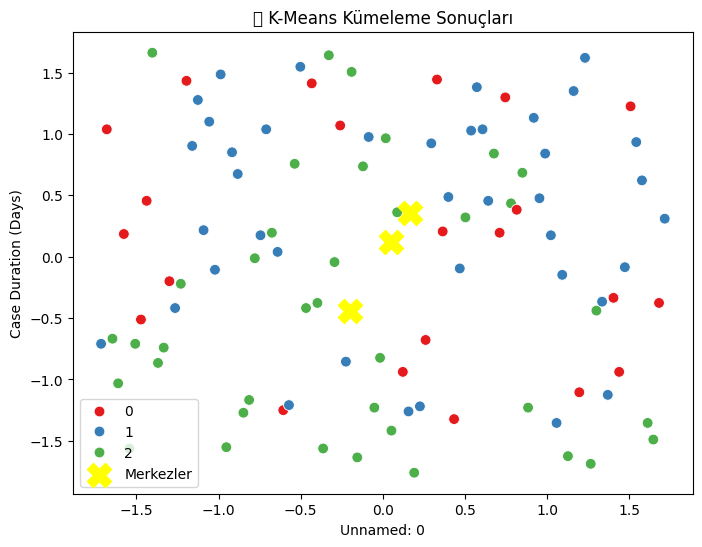

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

# Eğer en az 2 sayısal sütun varsa
if df_num.shape[1] >= 2:
    plt.figure(figsize=(8,6))

    # Scatter plot
    sns.scatterplot(
        x=data_scaled[:, 0],
        y=data_scaled[:, 1],
        hue=clusters,
        palette='Set1',
        s=60
    )

    # Küme merkezlerini ekle
    plt.scatter(
        kmeans.cluster_centers_[:,0],
        kmeans.cluster_centers_[:,1],
        s=300,
        c='yellow',
        label='Merkezler',
        marker='X'
    )

    plt.title("🎯 K-Means Kümeleme Sonuçları")
    plt.xlabel(num_cols[0])
    plt.ylabel(num_cols[1])
    plt.legend()
    plt.show()
else:
    print("⚠️ 2 boyuttan az özellik var, scatter plot çizilemiyor.")


In [16]:
# Her kümenin sayısal özelliklerin ortalaması
cluster_summary = data.groupby("Kume").mean()

print("📊 Küme Özellikleri Özeti:\n")
print(cluster_summary)


📊 Küme Özellikleri Özeti:

      Unnamed: 0  Case Duration (Days)  Number of Witnesses  Legal Fees (USD)  \
Kume                                                                            
0      50.863636            211.954545            13.000000      19764.636364   
1      54.275000            234.100000             8.300000      36180.175000   
2      43.684211            157.736842             6.842105      20030.394737   

      Number of Evidence Items  Severity   Outcome  
Kume                                                
0                    35.681818  2.227273  0.863636  
1                    32.775000  1.675000  0.150000  
2                    14.263158  1.763158  0.447368  
